# inspect reactome + and merge with kegg

Loaded 156 layers from ../multiplex_ts/layers
Loaded 22 layers from ../multiplex_2025hdrg/layers
Multiplex: 14,874 UniProt IDs → 14,713 gene symbols
KEGG columns: ['Unnamed: 0', 'gene_name', 'pathway_name', 'gene_name_uniprot', 'gene_name_symbol', 'gene_symbol']
KEGG shape:   (39334, 6)
   Unnamed: 0 gene_name                               pathway_name  \
0           0    hsa:10  Metabolic pathways - Homo sapiens (human)   
1           1   hsa:100  Metabolic pathways - Homo sapiens (human)   

  gene_name_uniprot gene_name_symbol gene_symbol  
0            A4Z6T7             NAT2        NAT2  
1        A0A0S2Z381              ADA         ADA  
Using KEGG symbol column: 'gene_name_symbol'
Using KEGG pathway column: 'pathway_name'

Reactome rows: 150,120
KEGG rows:     34,450

Pathway lookup: 12,835 unique gene symbols, 3,177 unique pathways

LR pairs with ≥1 shared pathway: 1,960 / 2,491 (78.7%)

Top 20 shared pathways:
    771  Signal Transduction
    401  Developmental Biology
    358

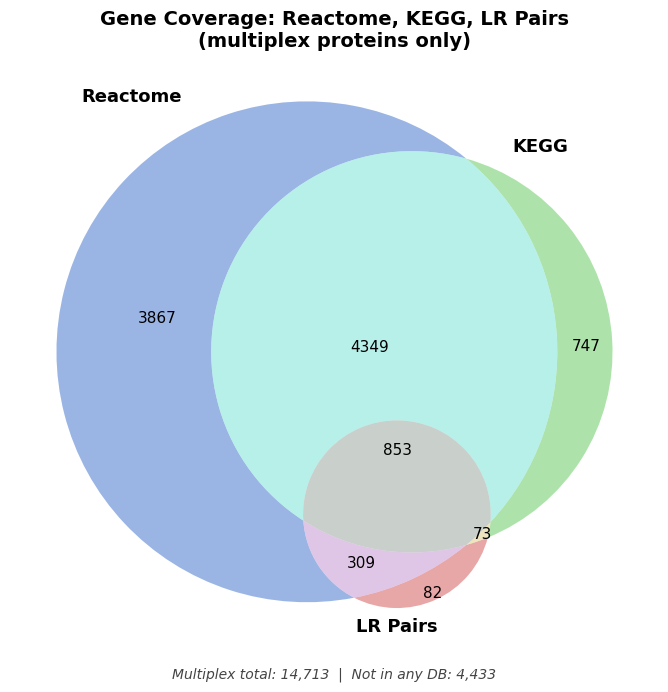

Saved venn_multiplex_coverage.png


In [2]:
import requests
import pandas as pd
import pickle
import os
import re
import networkx as nx
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib_venn import venn3

# ============================================================================
# 1. DOWNLOAD FUNCTIONS
# ============================================================================

def download_csv(url, output_file, sep='\t', header=None, col_names=None):
    """Generic downloader to avoid repeating try/except blocks."""
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    with open(output_file, 'w') as f:
        f.write(response.text)
    df = pd.read_csv(output_file, sep=sep, header=header)
    if col_names:
        df.columns = col_names
    return df


def download_interactions():
    return download_csv(
        url='https://download.reactome.org/96/interactors/reactome.homo_sapiens.interactions.tab-delimited.txt',
        output_file='reactome_interactions_human.txt',
        sep='\t',
        header=0  # this file HAS a header
    )


def download_uniprot_to_pathways():
    return download_csv(
        url='https://download.reactome.org/96/UniProt2Reactome_All_Levels.txt',
        output_file='uniprot_to_pathways.txt',
        col_names=['uniprot_id', 'reactome_id', 'url', 'pathway_name', 'evidence_code', 'species']
    )


def download_pathway_list():
    return download_csv(
        url='https://download.reactome.org/96/ReactomePathways.txt',
        output_file='pathway_list.txt',
        col_names=['reactome_id', 'pathway_name', 'species']
    )

# ============================================================================
# 2. LOAD LAYERS AND GET MULTIPLEX PROTEINS
# ============================================================================

def load_layers(layers_dir):
    layers = {}
    for fname in sorted(f for f in os.listdir(layers_dir) if f.endswith('_layer.pkl')):
        cell_type = fname.replace('_layer.pkl', '')
        with open(os.path.join(layers_dir, fname), 'rb') as f:
            layers[cell_type] = pickle.load(f)
    print(f"Loaded {len(layers)} layers from {layers_dir}")
    return layers


def get_multiplex_proteins(layers):
    """Return set of all node labels across all layers."""
    proteins = set()
    for layer in layers.values():
        proteins.update(layer.nodes())
    return proteins


def convert_nodes_to_uniprot(layers, symbol_to_uniprot):
    """Relabel graph nodes from gene symbols to UniProt IDs."""
    converted = {}
    for cell_type, layer in layers.items():
        mapping = {
            node: symbol_to_uniprot.get(str(node).upper(), node)
            for node in layer.nodes()
        }
        converted[cell_type] = nx.relabel_nodes(layer, mapping)
    return converted

# ============================================================================
# 3. BUILD PATHWAY LOOKUP  ← this is where your bug lives
# ============================================================================

def build_symbol_pathway_lookup(uniprot_pathways_df, kegg_pathways_df, uniprot_to_symbol):
    """
    Returns a DataFrame with columns:
        gene_symbol | pathway_names (pipe-sep) | sources (pipe-sep)
    """
    # ── Reactome (human only) ─────────────────────────────────────────────────
    reactome = (
        uniprot_pathways_df[uniprot_pathways_df['species'] == 'Homo sapiens']
        [['uniprot_id', 'pathway_name']]
        .copy()
    )
    reactome['gene_symbol'] = (
        reactome['uniprot_id'].map(uniprot_to_symbol).str.upper()
    )
    reactome['source'] = 'Reactome'
    reactome = reactome.dropna(subset=['gene_symbol'])[['gene_symbol', 'pathway_name', 'source']]

    # ── KEGG: diagnose columns first ─────────────────────────────────────────
    print(f"KEGG columns: {kegg_pathways_df.columns.tolist()}")
    print(f"KEGG shape:   {kegg_pathways_df.shape}")
    print(kegg_pathways_df.head(2))

    kegg_raw = kegg_pathways_df[
        ~kegg_pathways_df['gene_name_uniprot'].str.startswith('hsa:', na=False)
    ].copy()

    # Find the symbol column — handle whatever name it actually has
    possible_symbol_cols = ['gene_name_symbol', 'gene_symbol', 'symbol', 'gene_name']
    symbol_col = next((c for c in possible_symbol_cols if c in kegg_raw.columns), None)
    if symbol_col is None:
        raise ValueError(f"Cannot find symbol column in KEGG df. Columns: {kegg_raw.columns.tolist()}")
    print(f"Using KEGG symbol column: '{symbol_col}'")

    # Find the pathway name column
    possible_pathway_cols = ['pathway_name', 'pathway', 'pathway_description', 'name']
    pathway_col = next((c for c in possible_pathway_cols if c in kegg_raw.columns), None)
    if pathway_col is None:
        raise ValueError(f"Cannot find pathway column in KEGG df. Columns: {kegg_raw.columns.tolist()}")
    print(f"Using KEGG pathway column: '{pathway_col}'")

    # Build kegg with standardised column names
    kegg = pd.DataFrame({
        'gene_symbol': kegg_raw[symbol_col].str.upper(),
        'pathway_name': kegg_raw[pathway_col],
        'source': 'KEGG'
    })
    kegg = kegg.dropna(subset=['gene_symbol', 'pathway_name'])

    # Sanity check — make sure pathway_name isn't literally 'pathway'
    bad = (kegg['pathway_name'].str.strip().str.lower() == 'pathway').sum()
    if bad > 0:
        print(f"WARNING: {bad:,} KEGG rows have pathway_name = 'pathway' — dropping them")
        kegg = kegg[kegg['pathway_name'].str.strip().str.lower() != 'pathway']

    print(f"\nReactome rows: {len(reactome):,}")
    print(f"KEGG rows:     {len(kegg):,}")

    # ── Combine and collapse ──────────────────────────────────────────────────
    combined = pd.concat([reactome, kegg], ignore_index=True)

    lookup = (
        combined
        .groupby('gene_symbol', sort=False)
        .agg(
            pathway_names=pd.NamedAgg(column='pathway_name',
                                      aggfunc=lambda x: '|'.join(sorted(set(x)))),
            sources=pd.NamedAgg(column='source',
                                aggfunc=lambda x: '|'.join(sorted(set(x))))
        )
        .reset_index()
    )

    print(f"\nPathway lookup: {len(lookup):,} unique gene symbols, "
          f"{combined['pathway_name'].nunique():,} unique pathways")
    return lookup

# ============================================================================
# 4. MAP LR PAIRS TO PATHWAYS
# ============================================================================

def map_lr_to_pathways(lr_df, lookup_df):
    """
    Adds pathway columns to LR pairs dataframe.
    lookup_df must have columns: gene_symbol, pathway_names, sources
    """
    idx = lookup_df.set_index('gene_symbol')  # fast lookup

    def get_field(gene, field):
        gene_up = str(gene).upper() if pd.notna(gene) else None
        if gene_up and gene_up in idx.index:
            return idx.at[gene_up, field]
        return None

    result = lr_df.copy()
    result['ligand_pathways']   = result['ligand_gname'].map(lambda g: get_field(g, 'pathway_names'))
    result['ligand_sources']    = result['ligand_gname'].map(lambda g: get_field(g, 'sources'))
    result['receptor_pathways'] = result['receptor_gname'].map(lambda g: get_field(g, 'pathway_names'))
    result['receptor_sources']  = result['receptor_gname'].map(lambda g: get_field(g, 'sources'))

    def common_pathways(row):
        p1 = set(row['ligand_pathways'].split('|'))   if pd.notna(row['ligand_pathways'])   else set()
        p2 = set(row['receptor_pathways'].split('|')) if pd.notna(row['receptor_pathways']) else set()
        common = p1 & p2
        return '|'.join(sorted(common)) if common else None

    result['common_pathways']   = result.apply(common_pathways, axis=1)
    result['n_common_pathways'] = result['common_pathways'].apply(
        lambda x: len(x.split('|')) if pd.notna(x) else 0
    )
    return result

# ============================================================================
# 5. VENN DIAGRAM HELPER
# ============================================================================

def plot_venn(reactome_syms, kegg_syms, lr_syms, multiplex_syms, save_path='venn.png'):
    r_only  = reactome_syms - kegg_syms - lr_syms
    k_only  = kegg_syms - reactome_syms - lr_syms
    lr_only = lr_syms - reactome_syms - kegg_syms
    r_k     = (reactome_syms & kegg_syms) - lr_syms
    r_lr    = (reactome_syms & lr_syms) - kegg_syms
    k_lr    = (kegg_syms & lr_syms) - reactome_syms
    r_k_lr  = reactome_syms & kegg_syms & lr_syms
    in_none = multiplex_syms - reactome_syms - kegg_syms - lr_syms

    fig, ax = plt.subplots(figsize=(9, 7))
    v = venn3(
        subsets=(len(r_only), len(k_only), len(r_k),
                 len(lr_only), len(r_lr), len(k_lr), len(r_k_lr)),
        set_labels=('Reactome', 'KEGG', 'LR Pairs'),
        ax=ax, alpha=0.55,
        set_colors=('#4878CF', '#6ACC65', '#D65F5F'),
    )
    for lbl in v.set_labels:
        if lbl: lbl.set_fontsize(13); lbl.set_fontweight('bold')
    for lbl in v.subset_labels:
        if lbl: lbl.set_fontsize(11)

    ax.set_title('Gene Coverage: Reactome, KEGG, LR Pairs\n(multiplex proteins only)',
                 fontsize=14, fontweight='bold')
    ax.annotate(
        f"Multiplex total: {len(multiplex_syms):,}  |  Not in any DB: {len(in_none):,}",
        xy=(0.5, -0.04), xycoords='axes fraction',
        ha='center', fontsize=10, color='#444', style='italic'
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved {save_path}")

# ============================================================================
# MAIN PIPELINE
# ============================================================================

# --- Downloads ---
interactions_df      = download_interactions()
uniprot_pathways_df  = download_uniprot_to_pathways()

# --- UniProt <-> symbol mapping ---
mapping_df       = pd.read_csv('../../og_gene_set/ppi_chloe/d_uniprot_to_symbol_20251120.csv')
uniprot_to_symbol = dict(zip(mapping_df['uniprotid'], mapping_df['symbol']))
symbol_to_uniprot = {v.upper(): k for k, v in uniprot_to_symbol.items()}

# --- Layers ---
layers_1 = load_layers("../multiplex_ts/layers")
layers_2 = load_layers("../multiplex_2025hdrg/layers")
layers   = {**layers_1, **layers_2}

converted_layers  = convert_nodes_to_uniprot(layers, symbol_to_uniprot)
multiplex_proteins = get_multiplex_proteins(converted_layers)
multiplex_symbols  = {
    uniprot_to_symbol[p].upper()
    for p in multiplex_proteins if p in uniprot_to_symbol
}
print(f"Multiplex: {len(multiplex_proteins):,} UniProt IDs → {len(multiplex_symbols):,} gene symbols")

# --- KEGG ---
kegg_pathways_df = pd.read_csv("kegg_pathways_with_names_symbols.csv")

# --- Pathway lookup (the fixed version) ---
lookup_df = build_symbol_pathway_lookup(uniprot_pathways_df, kegg_pathways_df, uniprot_to_symbol)

# --- LR pairs ---
lr_pairs         = pd.read_csv('human_lr_pairs.csv')
lr_with_pathways = map_lr_to_pathways(lr_pairs, lookup_df)
lr_with_pathways.to_csv('lr_pairs_with_pathways.csv', index=False)

# Quick summary
total      = len(lr_with_pathways)
has_common = lr_with_pathways['common_pathways'].notna().sum()
print(f"\nLR pairs with ≥1 shared pathway: {has_common:,} / {total:,} "
      f"({100*has_common/total:.1f}%)")

print("\nTop 20 shared pathways:")
counter = Counter(
    p for val in lr_with_pathways['common_pathways'].dropna()
    for p in val.split('|')
)
for pathway, n in counter.most_common(20):
    print(f"  {n:>5}  {pathway}")

# --- Venn diagram ---
lr_syms       = (set(lr_pairs['ligand_gname'].str.upper().dropna()) |
                 set(lr_pairs['receptor_gname'].str.upper().dropna())) & multiplex_symbols
reactome_syms = set(lookup_df.loc[lookup_df['sources'].str.contains('Reactome', na=False), 'gene_symbol']) & multiplex_symbols
kegg_syms     = set(lookup_df.loc[lookup_df['sources'].str.contains('KEGG',     na=False), 'gene_symbol']) & multiplex_symbols

plot_venn(reactome_syms, kegg_syms, lr_syms, multiplex_symbols,
          save_path='venn_multiplex_coverage.png')